# Welcome to SMS Spam Detection!

In [116]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

file_path = project_folder / "data" / "spam_messages_train.csv"

train_df = pd.read_csv(file_path)

In [117]:
train_df.head()

,label,text
0,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
1,ham,I sent my scores to sophas and i had to do sec...
2,spam,We know someone who you know that fancies you....
3,ham,Only if you promise your getting out as SOON a...
4,spam,Congratulations ur awarded either �500 of CD g...


In [118]:
shape = train_df.shape
print(f"total rows: {shape[0]}")
print(f"total columns: {shape[1]}")

total rows: 47392
total columns: 2


In [119]:
train_df.info() # column names, types, non-null counts, memory summary

<class 'pandas.DataFrame'>
RangeIndex: 47392 entries, 0 to 47391
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   47392 non-null  str  
 1   text    47392 non-null  str  
dtypes: str(2)
memory usage: 740.6 KB


In [120]:
train_df["label"].value_counts()

label
ham     28560
spam    18832
Name: count, dtype: int64

# Data quality Check

## checking the nulll values

In [121]:
train_df.isnull().sum()

label    0
text     0
dtype: int64

## checking the duplicates 

In [122]:
duplicates = train_df.duplicated().sum()
print(f"total duplicate datas {duplicates}")

total duplicate datas 2823


## checking the empty messages such as white spaces 

In [123]:
train_df["text"].str.strip().eq("").sum()

np.int64(0)

# Investigating duplicates and labels

In [124]:
duplicates = train_df[
    train_df.duplicated(keep=False)
]

duplicates.head(10)

,label,text
7,ham,No message..no responce..what happend?
50,spam,HMV BONUS SPECIAL 500 pounds of genuine HMV vo...
51,ham,He remains a bro amongst bros
61,spam,Buy Space Invaders 4 a chance 2 win orig Arcad...
66,ham,As per your request 'Maangalyam (Alaipayuthe)'...
73,ham,Honeybee Said: *I'm d Sweetest in d World* God...
75,spam,WINNER!! As a valued network customer you have...
79,ham,Sad story of a Man - Last week was my b'day. M...
94,ham,"Sorry, I'll call later"
102,ham,Wat r u doing?


In [125]:
label_counts = train_df.groupby("text")["label"].nunique()

conflicting_messages = label_counts[label_counts > 1]

print("Messages with conflicting labels:", len(conflicting_messages))

Messages with conflicting labels: 1


In [126]:
train_df["text"].value_counts().head(10)

text
click here to be removed                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

# Train/ Validation/ test and overlaps

In [127]:
val_df = pd.read_csv(
    project_folder / "data" / "spam_messages_val.csv"
)

test_df = pd.read_csv(
    project_folder / "data" / "spam_messages_test.csv"
)

In [128]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (47392, 2)
Validation: (5923, 2)
Testing: (5926, 2)


## overlapping text between train and test

In [129]:
train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

common_messages = train_texts.intersection(test_texts)

print("Messages shared between train and test:", len(common_messages))

Messages shared between train and test: 624


In [130]:
train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print("Train vs Validation:",
      len(train_texts.intersection(val_texts)))

print("Train vs Test:",
      len(train_texts.intersection(test_texts)))

print("Validation vs Test:",
      len(val_texts.intersection(test_texts)))

Train vs Validation: 643
Train vs Test: 624
Validation vs Test: 99


In [131]:
# Create independent copies
train_clean = train_df.copy()
val_clean = val_df.copy()
test_clean = test_df.copy()

# Keep the test split as the reference
test_texts = set(test_clean["text"])

# Remove test messages from validation
val_clean = val_clean[
    ~val_clean["text"].isin(test_texts)
].copy()

# Remove validation and test messages from training
reserved_texts = set(val_clean["text"]) | test_texts

train_clean = train_clean[
    ~train_clean["text"].isin(reserved_texts)
].copy()

In [132]:
train_clean = train_clean.drop_duplicates().reset_index(drop=True)

val_clean = val_clean.drop_duplicates().reset_index(drop=True)

test_clean = test_clean.drop_duplicates().reset_index(drop=True)

In [133]:
print("Train:", train_clean.shape)
print("Validation:", val_clean.shape)
print("Test:", test_clean.shape)

print(
    "Train vs Validation:",
    len(set(train_clean["text"]) & set(val_clean["text"]))
)

print(
    "Train vs Test:",
    len(set(train_clean["text"]) & set(test_clean["text"]))
)

print(
    "Validation vs Test:",
    len(set(val_clean["text"]) & set(test_clean["text"]))
)

Train: (43321, 2)
Validation: (5755, 2)
Test: (5887, 2)
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


In [134]:
conflicts = train_clean.groupby("text")["label"].nunique()

print("Conflicting texts:", (conflicts > 1).sum())

Conflicting texts: 1


In [135]:
conflicts = train_clean.groupby("text")["label"].nunique()
print(conflicts)

conflicting_texts = conflicts[conflicts > 1].index

train_clean[train_clean["text"].isin(conflicting_texts)]

text
 & who wants to help millions ?  8 is our theme for enron  , s 2000 houston united way campaign , which officially kicks off on august 9 , 2000 . last year , enron achieved a 17 percent increase overour 1998 campaign . this success would not have been possible without the support of all levels of management . enron  , s executive solicitation begins today , and we are counting on your leadership and strong support this year . your generous contribution will enable united way agencies in our community to continue providing quality programs and services . our goal this year is $ 2 , 310 , 000  ) a challenging goal , but we believe it is achievable with your help . including the dollar for dollar corporate match , enron  , s total pledge to united way in 2000 will be more than $ 4 . 5 million . to get there , we invite you to  & help millions  8 by making your pledge in one of the following way : ? alexis de tocqueville society ( gifts of $ 10 , 000 or more )  ) every member

,label,text
21865,spam,hi
37796,ham,hi


In [136]:
train_clean = train_clean[
    ~train_clean["text"].isin(conflicting_texts)
].reset_index(drop=True)

In [137]:
print("Training rows:", len(train_clean))

conflicts = train_clean.groupby("text")["label"].nunique()

print("Conflicting texts:", (conflicts > 1).sum())

Training rows: 43319
Conflicting texts: 0


In [138]:
train_clean["label"].value_counts()

label
ham     27319
spam    16000
Name: count, dtype: int64

In [139]:
train_clean["label"].value_counts(normalize=True) * 100

label
ham     63.064706
spam    36.935294
Name: proportion, dtype: float64

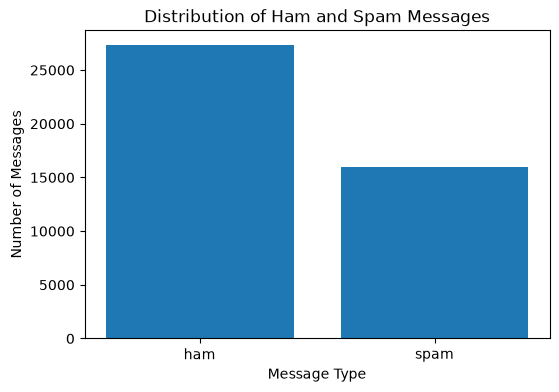

In [140]:
import matplotlib.pyplot as plt

label_counts = train_clean["label"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(label_counts.index, label_counts.values)

plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.title("Distribution of Ham and Spam Messages")

plt.show()

## Message Length Analysis

We calculate the number of characters in each message
to investigate whether spam and ham messages have
different length patterns.

In [141]:
train_clean["message_length"] = train_clean["text"].str.len()

train_clean[["label", "text", "message_length"]].head()

,label,text,message_length
0,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t...",151
1,ham,I sent my scores to sophas and i had to do sec...,221
2,spam,We know someone who you know that fancies you....,101
3,ham,Only if you promise your getting out as SOON a...,124
4,spam,Congratulations ur awarded either �500 of CD g...,148


In [142]:
train_clean.groupby("label")["message_length"].mean()

label
ham     839.941616
spam    970.128687
Name: message_length, dtype: float64

In [143]:
train_clean.groupby("label")["message_length"].agg(
    ["min", "max", "mean", "median"]
)

,min,max,mean,median
label,,,,
ham,1,228353,839.941616,329.0
spam,2,28688,970.128687,442.0


## Message Length Distribution

We use a histogram to understand how message lengths are distributed
and identify whether unusually long messages affect the dataset.

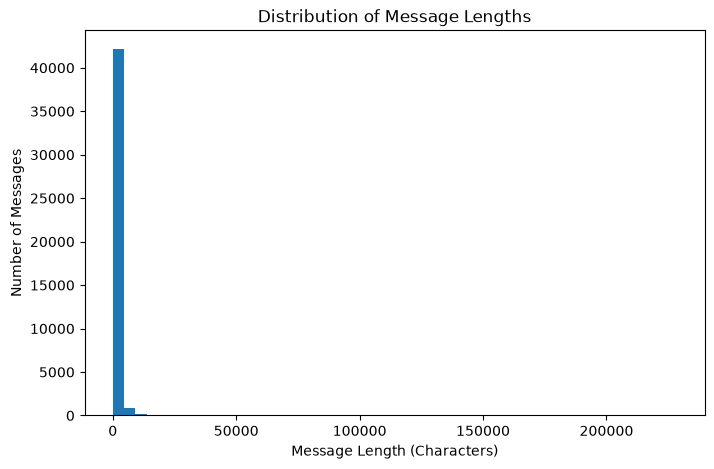

In [144]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(train_clean["message_length"], bins=50)

plt.xlabel("Message Length (Characters)")
plt.ylabel("Number of Messages")
plt.title("Distribution of Message Lengths")

plt.show()

In [145]:
train_clean["message_length"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

0.50     385.00
0.75     800.00
0.90    2007.20
0.95    3157.10
0.99    7670.28
Name: message_length, dtype: float64

In [146]:
limit = train_clean["message_length"].quantile(0.95)

print("95th percentile:", limit)

95th percentile: 3157.0999999999985


In [147]:
shorter_messages = train_clean[
    train_clean["message_length"] <= limit
]

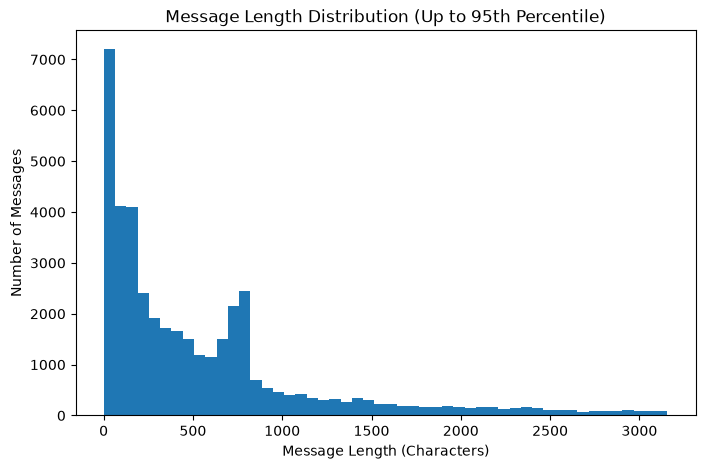

In [148]:
plt.figure(figsize=(8, 5))

plt.hist(shorter_messages["message_length"], bins=50)

plt.xlabel("Message Length (Characters)")
plt.ylabel("Number of Messages")
plt.title("Message Length Distribution (Up to 95th Percentile)")

plt.show()